### generate synthetic data

This example is drawn from the Simo Sarkka textbook Bayesian Filtering and Smoothing exercise 5.5 and 5.6. 

In [1]:
import numpy as np
from scipy.linalg import expm

import matplotlib.pyplot as plt


S1 = np.array([-1.5, 0.5])   # Position of sensor 1
S2 = np.array([1.0, 1.0])    # Position of sensor 2
sd = 0.05                    # Standard deviation of measurements
dt = 0.01                    # Sampling period
x0 = np.array([0.0, 0.0, 1.0, 0.0])  # Initial state

# Initialize
a = np.zeros(500)

# Fill segments with angular velocity + noise
a[49:100]  = (np.pi / 2 / 51 / dt) + 0.01 * np.random.randn(51)
a[199:250] = (np.pi / 2 / 51 / dt) + 0.01 * np.random.randn(51)
a[349:400] = (np.pi / 2 / 51 / dt) + 0.01 * np.random.randn(51)

x = x0.copy()
t = 0.0
X = []
Theta = []
T = []

# Main loop
for i in range(500):
    F = np.array([
        [0, 0,  1,     0],
        [0, 0,  0,     1],
        [0, 0,  0,   a[i]],
        [0, 0, -a[i],  0]
    ])
    
    # State propagation
    x = expm(F * dt) @ x

    # Noisy angle measurements
    y1 = np.arctan2(x[1] - S1[1], x[0] - S1[0]) + sd * np.random.randn()
    y2 = np.arctan2(x[1] - S2[1], x[0] - S2[0]) + sd * np.random.randn()

    t += dt
    X.append(x.copy())
    T.append(t)
    Theta.append([y1, y2])

# Convert lists to arrays
X = np.column_stack(X)
T = np.array(T)
Theta = np.column_stack(Theta)

steps = Theta.shape[1]



### Baseline example using triangulation

In [2]:
# Initialize
m1 = x0.copy()
EST1 = np.zeros((4, steps))

# Implement RMSE (true and estimate)
def rmse(X, EST):
    return np.sqrt(np.mean(np.sum((X - EST)**2, axis=0)))



# Loop through steps
for k in range(steps):

    # Compute crossing of the measurements
    dx1 = np.cos(Theta[0, k])
    dy1 = np.sin(Theta[0, k])
    dx2 = np.cos(Theta[1, k])
    dy2 = np.sin(Theta[1, k])

    A = np.array([[dx1, dx2],
                  [dy1, dy2]])
    b = np.array([S2[0] - S1[0],
                  S2[1] - S1[1]])

    d = np.linalg.solve(A, b)

    # Crossing point
    cross_xy = S1 + np.array([dx1, dy1]) * d[0]

    # Compute estimate
    m1[2:4] = np.array([0.0, 0.0])   # velocities set to zero
    m1[0:2] = cross_xy
    EST1[:, k] = m1


# Compute error
err1 = rmse(X, EST1)
print("Baseline RMSE:", err1)




Baseline RMSE: 1.0184957222032471


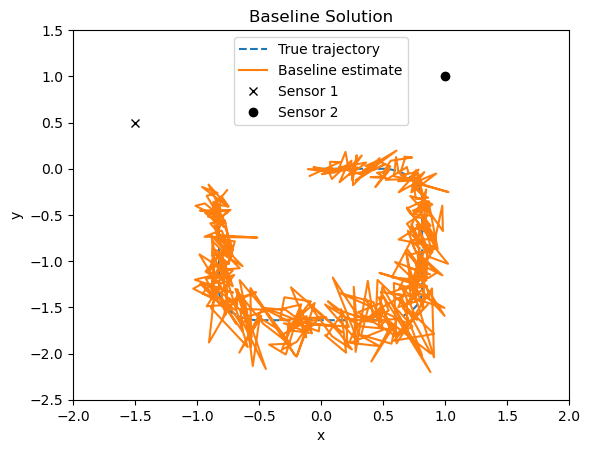

In [3]:
# Plot baseline result
plt.figure(1)
plt.clf()
plt.plot(X[0, :], X[1, :], '--',
         EST1[0, :], EST1[1, :], '-',
         S1[0], S1[1], 'kx',
         S2[0], S2[1], 'ko')

plt.legend(['True trajectory', 'Baseline estimate', 'Sensor 1', 'Sensor 2'])
plt.xlabel('x')
plt.ylabel('y')
plt.title('Baseline Solution')
plt.axis([-2, 2, -2.5, 1.5])
plt.show()


In [4]:
# code to store images/ data in a distinct folder structure
import os
from datetime import datetime

# printing to external directory
def get_timestamp_dir(base_dir):
    timestamp = datetime.now().strftime("%Y-%m-%d_%H:%M.%S")
    return os.path.join(base_dir, timestamp)


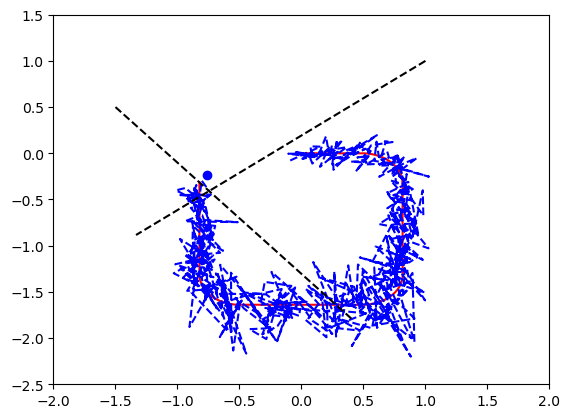

In [5]:
out_dir = get_timestamp_dir("output/baseline")
os.mkdir(out_dir)

# printing baseline
for k in range(steps):
    if k % 10 == 0:
        length = 3.0
        dx1p = length * np.cos(Theta[0, k])
        dy1p = length * np.sin(Theta[0, k])
        dx2p = length * np.cos(Theta[1, k])
        dy2p = length * np.sin(Theta[1, k])

        plt.clf()
        plt.plot(X[0, :], X[1, :], 'r-',
                    m1[0], m1[1], 'bo',
                    EST1[0, :k+1], EST1[1, :k+1], 'b--',
                    [S1[0], S1[0] + dx1p], [S1[1], S1[1] + dy1p], 'k--',
                    [S2[0], S2[0] + dx2p], [S2[1], S2[1] + dy2p], 'k--')

        plt.axis([-2, 2, -2.5, 1.5])

        filename = os.path.join(out_dir, f"frame_{k:04d}.png")


        plt.savefig(filename, dpi=150, bbox_inches="tight")

        # plt.pause(0.1)

### Extended Kalman Filter 

#### model

In [ ]:
import math # for pow

m = x0.copy()#.reshape(4, 1)
P = np.eye(4)

s_residual = []
s_predicted = []

MM = np.zeros((m.shape[0], steps))
PP = np.zeros((P.shape[0], P.shape[1], steps))

# setup the transition function & the gaussian process noise function 
F = np.array([[1, 0, dt, 0],
              [0, 1, 0, dt],
              [0, 0, 1, 0],
              [0, 0, 0, 1]])

def get_process_noise():
    qc1 = 0.1
    qc2 = 0.1
    return np.array([[(qc1 * math.pow(dt, 3) / 3), 0, (qc1 * math.pow(dt, 2) / 2), 0],
                    [0, (qc2 * math.pow(dt, 3)/3), 0, (qc2 * math.pow(dt, 2)/2)],
                    [(qc1 * math.pow(dt, 2)/2), 0, (qc1 * dt), 0],
                    [0, qc2 * math.pow(dt, 2)/2, 0, (qc2 * dt)]])

Q = get_process_noise()


# measurement function
# TODO is this correct? don't really understand why
R = np.array([0.05**2])  # make measurement noise a gaussian distribution

def measurement_function(x_state, sensor):
    """returns the angle given the x_state"""
    x = x_state[0]
    y = x_state[1]
    s_x = sensor[0]
    s_y = sensor[1]
    return math.atan2((y - s_y), (x - s_x))

def get_measurement_jacobian_matrix(x_state, sensor):
    """returns the jacobian  matrix at x_state for a given sensor"""
    x = x_state[0].item()
    y = x_state[1].item()
    s_x = sensor[0].item()
    s_y = sensor[1].item()
    term_1 = (y - s_y) / (((x - s_x)**2) + ((y-s_y)**2))
    term_2 = -(x - s_x) / (((x - s_x)**2) + ((y - s_y)**2))
    return np.array([[term_1, term_2, 0, 0]])


for i in range(steps):
    # measurements for current step
    theta_sensor_1 = Theta[0, i]
    theta_sensor_2 = Theta[1, i]


    # prediction step
    m = F @ m
    P = F @ P @ F.T + Q


    # just doing measurement update for S1
    ## calculate measurement matrix for current state estimate
    #for sensor_values in [(S2, theta_sensor_2)]:
    for sensor_values in [(S1, theta_sensor_1)]:
        H = get_measurement_jacobian_matrix(m, sensor_values[0])
        h = measurement_function(m, sensor_values[0])
        # calculate residual 
        y = sensor_values[1] - h

        S = H @ P @ H.T  + R
        K = P @ H.T / S
        P = P - K @ S @ K.T

        m = m + (K.flatten() * y) 

    # store 
    s_residual.append(y)
    s_predicted.append(h)
    MM[:, i] = m#.reshape(-1)
    PP[:, :, i] = P

#### visualising the data

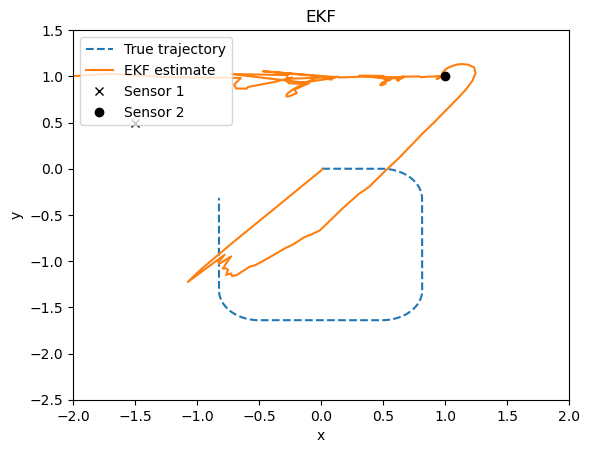

In [14]:
# plotting baseline solution 
plt.figure(1)
plt.clf()
plt.plot(X[0, :], X[1, :], '--',
         MM[0, :], MM[1, :], '-',
         #EST1[0, :], EST1[1, :], '-',
         S1[0], S1[1], 'kx',
         S2[0], S2[1], 'ko')

plt.legend(['True trajectory', 'EKF estimate', 'Sensor 1', 'Sensor 2'])
plt.xlabel('x')
plt.ylabel('y')
plt.title('EKF')
plt.axis([-2, 2, -2.5, 1.5])
plt.show()


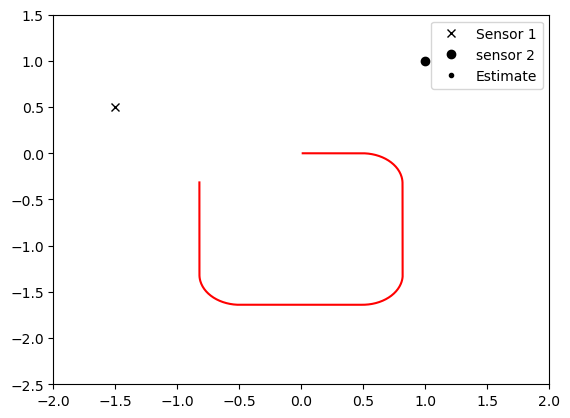

In [15]:
# breaking into frame by frame
out_dir = get_timestamp_dir("output/EKF")
os.mkdir(out_dir)



for k in range(steps):
    if k % 5 == 0:

        plt.clf()
        plt.plot(X[0, :], X[1, :], 'r-')
        plt.plot(S1[0], S1[1], 'kx', label="Sensor 1")
        plt.plot(S2[0], S2[1], 'ko', label="sensor 2")
        plt.plot(MM[0,k], MM[1,k],  'k.', linewidth=5, label='Estimate')
        plt.legend()

                 #[MM[0, k]], [MM[1, k]], 'b--', linewidth=5, label='Estimatb--', linewidth=5, label='Estimate')

        plt.axis([-2, 2, -2.5, 1.5])

        filename = os.path.join(out_dir, f"frame_{k:04d}.png")
        plt.savefig(filename, dpi=150, bbox_inches="tight")
 
 
    

In [ ]:
# plot the residual over time (measurement error, etc)